Using backend: tensorflow

2022-11-09 16:18:34.771977: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcudart.so.11.0
2022-11-09 16:18:36.009962: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcuda.so.1
2022-11-09 16:18:36.082513: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1733] Found device 0 with properties: 
pciBusID: 0000:81:00.0 name: Quadro RTX 8000 computeCapability: 7.5
coreClock: 1.77GHz coreCount: 72 deviceMemorySize: 47.46GiB deviceMemoryBandwidth: 625.94GiB/s
2022-11-09 16:18:36.082538: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcudart.so.11.0
2022-11-09 16:18:36.085068: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublas.so.11
2022-11-09 16:18:36.085099: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dyn

Enable just-in-time compilation with XLA.

Disable just-in-time compilation with XLA.

[1, 1000]
no uniform points
Compiling model...
'compile' took 0.000435 s



2022-11-09 16:18:37.105890: I tensorflow/core/platform/cpu_feature_guard.cc:142] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2022-11-09 16:18:37.112328: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1733] Found device 0 with properties: 
pciBusID: 0000:81:00.0 name: Quadro RTX 8000 computeCapability: 7.5
coreClock: 1.77GHz coreCount: 72 deviceMemorySize: 47.46GiB deviceMemoryBandwidth: 625.94GiB/s
2022-11-09 16:18:37.117340: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1871] Adding visible gpu devices: 0
2022-11-09 16:18:37.117438: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcudart.so.11.0
2022-11-09 16:18:37.584710: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1258] Device interconnect StreamExecu

Training model...



2022-11-09 16:18:40.229416: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:176] None of the MLIR Optimization Passes are enabled (registered 2)
2022-11-09 16:18:40.258275: I tensorflow/core/platform/profile_utils/cpu_utils.cc:114] CPU Frequency: 3000030000 Hz
2022-11-09 16:18:40.470472: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublas.so.11
2022-11-09 16:18:40.840004: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublasLt.so.11


Step      Train loss              Test loss               Test metric
0         [8.39e+05, 2.59e+01]    [8.58e+05, 2.55e+01]    []  
1000      [1.30e+04, 3.33e+04]    [1.38e+04, 3.54e+04]    []  
2000      [9.18e+03, 2.37e+04]    [9.77e+03, 2.58e+04]    []  
3000      [8.47e+03, 2.09e+04]    [9.04e+03, 2.32e+04]    []  
4000      [6.21e+03, 1.90e+04]    [6.68e+03, 2.15e+04]    []  
5000      [3.95e+03, 1.75e+04]    [4.21e+03, 2.00e+04]    []  
6000      [2.89e+03, 1.46e+04]    [3.11e+03, 1.69e+04]    []  
7000      [2.80e+03, 1.21e+04]    [2.92e+03, 1.40e+04]    []  
8000      [1.93e+03, 1.03e+04]    [2.07e+03, 1.21e+04]    []  
9000      [1.56e+03, 8.80e+03]    [1.67e+03, 1.03e+04]    []  
10000     [1.68e+03, 7.56e+03]    [1.80e+03, 8.95e+03]    []  
11000     [1.35e+03, 7.95e+03]    [1.41e+03, 9.22e+03]    []  
12000     [8.36e+02, 7.08e+03]    [9.06e+02, 8.40e+03]    []  
13000     [1.03e+03, 5.87e+03]    [1.09e+03, 7.09e+03]    []  
14000     [7.51e+02, 4.98e+03]    [8.14e+02, 6.0

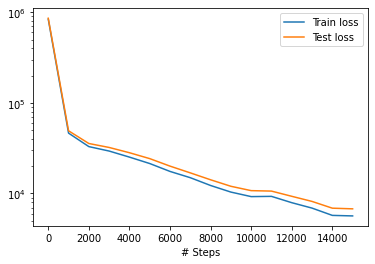

In [1]:
import os
os.environ['DDEBACKEND'] = 'tensorflow'
os.environ['CUDA_VISIBLE_DEVICES'] = '4'

import deepxde as dde 
dde.config.disable_xla_jit()

#class TensorGeometryXTime:
import numpy as np

class GeometryXGeometry:
    def __init__(self, geometry, k):
        self.geometry = geometry
        self.dim = geometry.dim ** k
        self.k = k
    
    def random_points(self, n, random="pseudo"):
        xx = []
        for i in range(self.k):
            xx.append(self.geometry.random_points(n, random=random))
        return np.hstack(xx)
    
    def uniform_points(self, n, boundary=False):
        print('no uniform points')
        return self.random_points(n)
    

"""Backend supported: tensorflow.compat.v1, tensorflow, pytorch"""
import deepxde as dde
import numpy as np

# General parameters
n = 1
k = 2

N_f = 5000
N_f_test = 5000

seed = 1234
dde.config.set_random_seed(seed)
weights = [1000 for i in range(k)]
weights[0] = 1
print(weights)

epochs = 15000

parameters = [1e-2, 2, 350, "sin"] 

# Define sine function
if dde.backend.backend_name == "pytorch":
    sin = dde.backend.pytorch.sin
else:
    from deepxde.backend import tf
    sin = tf.sin

learning_rate, num_dense_layers, num_dense_nodes, activation = parameters


def pde(x, y):
    V0, V1 = y[:, 0:1], y[:, 1:2]
    
    dV0_xx = dde.grad.hessian(y, x, component=0, i=0, j=0)
    dV0_yy = dde.grad.hessian(y, x, component=0, i=1, j=1)
    
    dV1_xx = dde.grad.hessian(y, x, component=1, i=2, j=2)
    dV1_yy = dde.grad.hessian(y, x, component=1, i=3, j=3)
    
    
    dist = tf.abs(x[:, 0:1] - x[:, 2:3]) ** 2
    F =  k0 ** 4 * tf.exp(- dist * 10)
    #F =  tf.exp(- dist * 10)
    L1 = - dV0_xx - dV0_yy - k0 ** 2 * V0 - F
    L2 = - dV1_xx - dV1_yy - k0 ** 2 * V1 - V0
    return [L1, L2]


def func(x):
    f1 = np.sin(k0 * x[:, 0:1]) * np.sin(k0 * x[:, 1:2])
    f2 = np.sin(k0 * x[:, 2:3]) * np.sin(k0 * x[:, 3:4])

    res_list = k * [None]
    
    for i in range(k-1):
        res_list[i] = 0 * f1
    res_list[-1] = f1 * f2
    return np.hstack(res_list)


def transform(x, y):
    res1 = x[:, 0:1] * (1 - x[:, 0:1]) * x[:, 1:2] * (1 - x[:, 1:2])
    res2 = x[:, 2:3] * (1 - x[:, 2:3]) * x[:, 3:4] * (1 - x[:, 3:4])

    y_list = [y[:, i:i+1] for i in range(k)]
    
    ys_list = k * [None]
    for i in range(k-1):
        ys_list[i] = y_list[i]
    ys_list[-1] = res1 * res2 * y_list[-1]
    ys = tf.concat(ys_list, axis=1)
    return ys


geom = dde.geometry.Rectangle([0, 0], [1, 1])
Geom = GeometryXGeometry(geom,2)    

k0 = 2 * np.pi * n
wave_len = 1 / n

data = dde.data.PDE(
    Geom,
    pde,
    train_distribution = 'pseudo',
    num_domain=N_f,
    bcs = [],
    num_test=N_f_test,
)

net = dde.nn.FNN(
    [2 * k] + [num_dense_nodes] * num_dense_layers + [k], activation, "Glorot uniform"
)

net.apply_output_transform(transform)

model = dde.Model(data, net)

model.compile("adam", lr=learning_rate, loss_weights=weights)
#model.compile("adam", lr=learning_rate, metrics=[l2_error], loss_weights=weights, decay = ("inverse time", 10000, 0.5))

losshistory, train_state = model.train(epochs=epochs)
dde.saveplot(losshistory, train_state, issave=True, isplot=True)
    

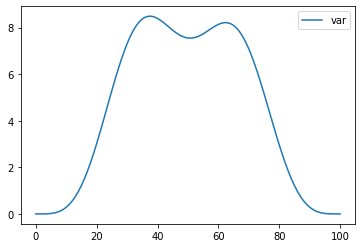

In [2]:
from matplotlib import pyplot as plt
x = np.array([np.arange(101)/100]).T
x_list = [x.T for i in range(2 * k)]
xx = np.concatenate(x_list).T
sol = func(xx)[:, k-1:k]
pred = model.predict(xx)[:, k-1:k]

plt.plot(pred.ravel(), label=r'var')
plt.legend()

In [7]:
u_sca.min(), u_sca.max()
# (0.0, 11.486398)

(0.0, 11.486398)

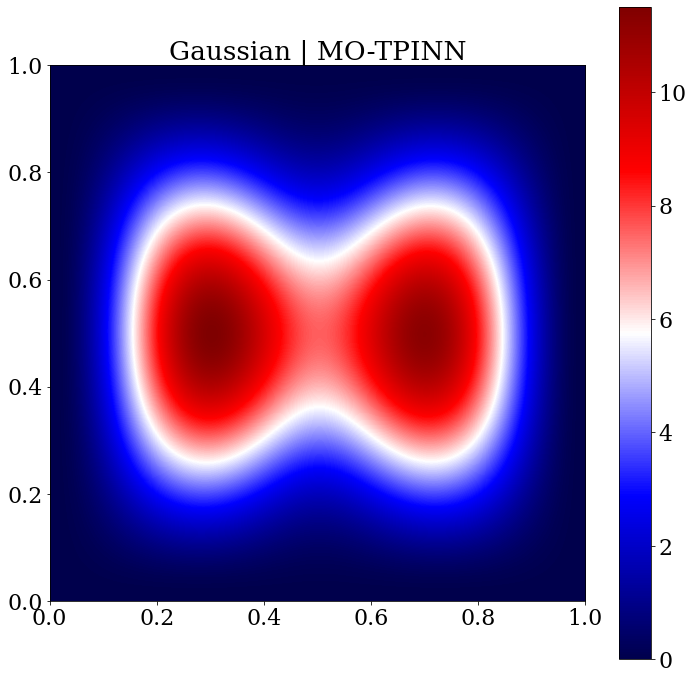

In [14]:
from matplotlib import pyplot as plt
'''            Evaluate field over a specified grid of points              '''
# Square grid with 10 points per wavelength in each direction
Nx = 100
Ny = Nx

vmin = 0 
vmax = 11.5

# Grid points
xmin, xmax, ymin, ymax = [0,1,0,1]
plot_grid = np.mgrid[xmin:xmax:Nx * 1j, ymin:ymax:Ny * 1j]
points = np.vstack((plot_grid[0].ravel(),
                    plot_grid[1].ravel(),
                    np.zeros(plot_grid[0].size)))

points_2d = points[:2, :]
points_4d = np.hstack([points_2d.T, points_2d.T])

u_sca = model.predict(points_4d)[:, k-1:k]
u_sca = u_sca.reshape((Nx, Ny))

'''                  Compare against analytical solution                    '''
# Uncomment to perform comparison, takes a few seconds to run


'''                     Plot field and save figure                          '''
plt.rc('font', family='serif', size=22)



fig, (ax1) = plt.subplots(1, 1, sharey=True, figsize = (12,12))

pcm = ax1.imshow(np.fliplr(u_sca).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label='MO-TPINNs', vmin=vmin, vmax=vmax)

#ax1.axis('off')
fig.colorbar(pcm, ax = ax1)
ax1.set_title('Gaussian | MO-TPINN')
plt.savefig('Gaussian-MO.pdf')

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


0.0 1558.5454565440386


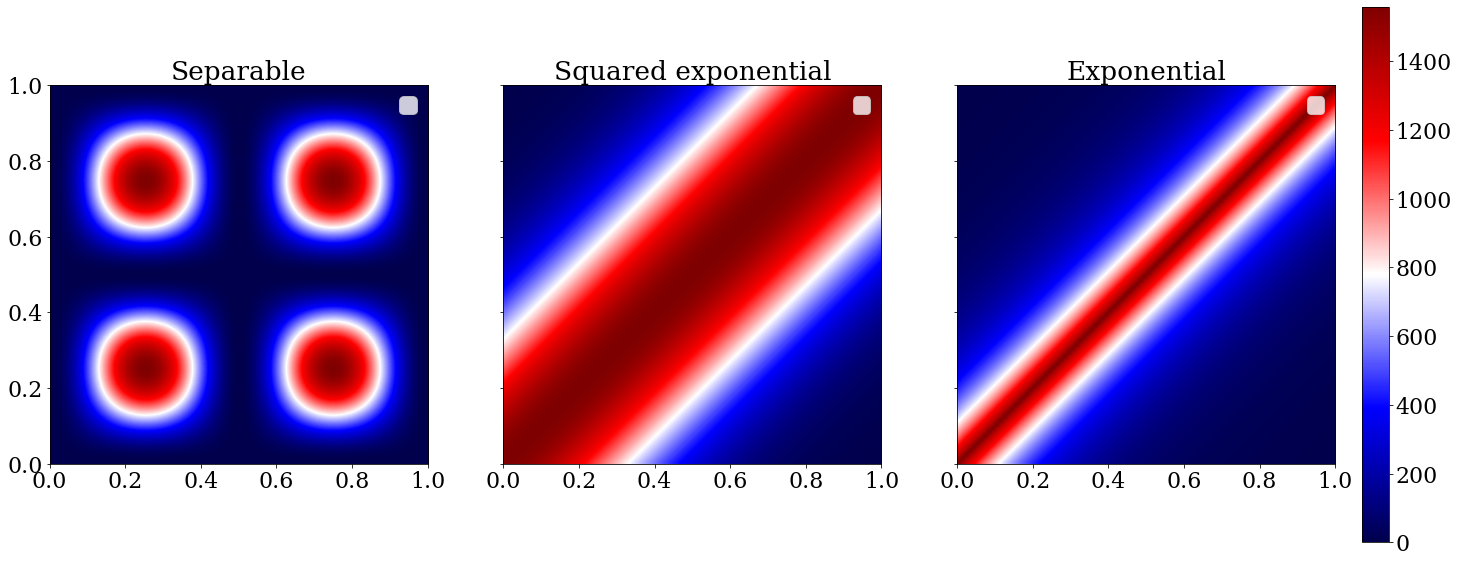

In [4]:

    from matplotlib import pyplot as plt
'''            Evaluate field over a specified grid of points              '''
# Square grid with 10 points per wavelength in each direction
Nx = 100
Ny = Nx

# Grid points
xmin, xmax, ymin, ymax = [0,1,0,1]
plot_grid = np.mgrid[xmin:xmax:Nx * 1j, ymin:ymax:Ny * 1j]
points = np.vstack((plot_grid[0].ravel(),
                    plot_grid[1].ravel(),
                    np.zeros(plot_grid[0].size)))

x = points.T


F1 = k0 ** 4 * np.sin(k0 * x[:, 0:1]) * np.sin(k0 * x[:, 1:2]) * np.sin(k0 * x[:, 0:1]) * np.sin(k0 * x[:, 1:2])
F1 = F1.reshape((Nx, Ny))    


dist = np.abs(x[:, 0:1] - x[:, 1:2]) ** 2
F2 = k0 ** 4 * np.exp(- dist * k0)
F2 = F2.reshape((Nx, Ny))    


dist = np.abs(x[:, 0:1] - x[:, 1:2])
F3 =  k0 ** 4 * np.exp(- dist * k0)
F3 = F3.reshape((Nx, Ny))    

vmin = np.min([F1,F2,F3])
vmax = np.max([F1,F2,F3])

print(vmin, vmax)


'''                  Compare against analytical solution                    '''
# Uncomment to perform comparison, takes a few seconds to run


'''                     Plot field and save figure                          '''
plt.rc('font', family='serif', size=22)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, sharey=True, figsize = (24,12))

pcm = ax1.imshow(np.fliplr(F1).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', vmin=vmin, vmax=vmax)

#fig.colorbar(pcm, ax = ax1)

pcm = ax2.imshow(np.fliplr(F2).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', vmin=vmin, vmax=vmax)

#fig.colorbar(pcm, ax = ax2)

pcm = ax3.imshow(np.fliplr(F3).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', vmin=vmin, vmax=vmax)
#ax1.axis('off')

fig.colorbar(pcm, ax=[ax1,ax2,ax3],fraction=0.02, pad=0.02)
#fig.colorbar(pcm)
ax1.legend()
ax2.legend()
ax3.legend()
ax1.set_title('Separable')
ax2.set_title('Squared exponential')
ax3.set_title('Exponential')
plt.savefig('kernels.pdf')

In [17]:
losshistory.loss_train

[array([8.3879725e+05, 2.5881281e+01], dtype=float32),
 array([13047.853, 33313.805], dtype=float32),
 array([ 9182.513, 23724.777], dtype=float32),
 array([ 8472.379, 20928.504], dtype=float32),
 array([ 6206.762, 18996.844], dtype=float32),
 array([ 3950.8667, 17459.148 ], dtype=float32),
 array([ 2892.461, 14625.146], dtype=float32),
 array([ 2799.2617, 12139.65  ], dtype=float32),
 array([ 1925.9211, 10329.248 ], dtype=float32),
 array([1560.9476, 8804.733 ], dtype=float32),
 array([1675.1984, 7562.079 ], dtype=float32),
 array([1348.8022, 7947.866 ], dtype=float32),
 array([ 836.1998, 7081.4194], dtype=float32),
 array([1025.4731, 5872.767 ], dtype=float32),
 array([ 750.53986, 4982.858  ], dtype=float32),
 array([ 879.4757, 4777.195 ], dtype=float32)]